# Segmentation evaluation on Colab

This notebook measures how well the trained 3D U-Net segments and names the vertebrae T10–L5, then runs the final test once.



## 0. Connect Google Drive and check the GPU
Gives the notebook access to your Drive, and stops early if no GPU is attached.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import torch
assert torch.cuda.is_available(), 'GPU is off: Runtime > Change runtime type > T4 GPU, then run again'
print('GPU:', torch.cuda.get_device_name(0))

Mounted at /content/drive
GPU: Tesla T4


## 1. Prepare the project
Copies the repository from Drive to the fast local disk, adds the evaluation code on top, and copies the model file.

It prints where each input was found. No line should say `NOT FOUND`. If your Drive folder has another name, change `FOLDER`.

The second cell installs two libraries and prints the model's epoch (54) and its validation Dice from training (0.646).

In [2]:
# ---- settings ----
DRIVE_ROOT = '/content/drive/MyDrive'
FOLDER = f'{DRIVE_ROOT}/Pedicle-Screw-Depth-Prediction'   # the Drive folder that holds your files
RUN = 'baseline_96'
VERSE_URL = 'https://s3.bonescreen.de/public/VerSe-complete'
# -------------------

import csv, hashlib, os, shutil, subprocess, zipfile
from pathlib import Path

REPO = Path('/content/repo')
os.environ['PYTHONUNBUFFERED'] = '1'


def sh(cmd):
    """Run a shell command in the repo, stream its output, stop on failure."""
    print('$', cmd, flush=True)
    p = subprocess.Popen(cmd, shell=True, cwd=REPO, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end='', flush=True)
    if p.wait() != 0:
        raise RuntimeError(f'command failed (exit {p.returncode}): {cmd}')


def locate(root, marker):
    """Shallowest folder under root that contains marker (handles double-nested unzips)."""
    hits = sorted(Path(root).glob(f'**/{marker}'), key=lambda p: len(p.parts))
    if not hits:
        raise FileNotFoundError(f'{marker} not found under {root}')
    return hits[0].parents[len(Path(marker).parts) - 1]


def find_input(*names):
    """First match in FOLDER, then MyDrive, then any folder directly under MyDrive."""
    for base in (FOLDER, DRIVE_ROOT):
        for n in names:
            if (Path(base) / n).exists():
                return Path(base) / n
    for n in names:
        hits = sorted(Path(DRIVE_ROOT).glob(f'*/{n}'))
        if hits:
            return hits[0]
    return None


OUT_BASE = Path(FOLDER) if Path(FOLDER).is_dir() else Path(DRIVE_ROOT)
REPO_ON_DRIVE = find_input('Pedicle-Screw-Depth-Prediction-main', 'Pedicle-Screw-Depth-Prediction-main.zip')
EVAL_ZIP = find_input('segmentation_evaluation.zip')
CHECKPOINT = find_input('best.pt.zip', 'best.pt')          # must be the ORIGINAL file, not unzipped
PROCESSED_ZIP = find_input('processed.zip')                # preprocessed data (optional)
VERSE_ON_DRIVE = OUT_BASE / 'VerSe2020'                    # VerSe zips are kept here
RESULTS = OUT_BASE / 'evaluation_results'
for label, path in (('repository', REPO_ON_DRIVE), ('evaluation zip', EVAL_ZIP), ('checkpoint', CHECKPOINT),
                    ('processed.zip', PROCESSED_ZIP), ('outputs go to', OUT_BASE)):
    print(f'{label:14s}: {path or "NOT FOUND"}')
if EVAL_ZIP is None:
    raise FileNotFoundError(f'segmentation_evaluation.zip not found in {FOLDER} or MyDrive')

# repository (folder or zip, possibly nested)
src = REPO_ON_DRIVE or Path(FOLDER)
if src.suffix == '.zip':
    shutil.rmtree('/tmp/repo_unzip', ignore_errors=True)
    zipfile.ZipFile(src).extractall('/tmp/repo_unzip')
    src = Path('/tmp/repo_unzip')
repo_src = locate(src, 'scripts/prepare_data.py')
shutil.rmtree(REPO, ignore_errors=True)
shutil.copytree(repo_src, REPO)

# evaluation code on top of it
shutil.rmtree('/tmp/eval_code', ignore_errors=True)
zipfile.ZipFile(EVAL_ZIP).extractall('/tmp/eval_code')
shutil.copytree(locate('/tmp/eval_code', 'scripts/evaluate_segmentation.py'), REPO, dirs_exist_ok=True)

# checkpoint: must be a FILE
ck = CHECKPOINT if CHECKPOINT is not None and CHECKPOINT.is_file() else None
if ck is None:
    raise FileNotFoundError('best.pt is not a file in Drive. Delete the unzipped best.pt folder and upload '
                            'the original best.pt.zip as it is (do not unzip it).')
shutil.copy(ck, REPO / 'best.pt')
os.chdir(REPO)
print('repo      :', repo_src)
print('checkpoint:', ck, '| sha256', hashlib.sha256((REPO / 'best.pt').read_bytes()).hexdigest()[:12])

repository    : /content/drive/MyDrive/Pedicle-Screw-Depth-Prediction /Pedicle-Screw-Depth-Prediction-main
evaluation zip: /content/drive/MyDrive/Pedicle-Screw-Depth-Prediction /segmentation_evaluation.zip
checkpoint    : /content/drive/MyDrive/Pedicle-Screw-Depth-Prediction /best.pt.zip
processed.zip : /content/drive/MyDrive/Pedicle-Screw-Depth-Prediction /processed.zip
outputs go to : /content/drive/MyDrive
repo      : /content/drive/MyDrive/Pedicle-Screw-Depth-Prediction /Pedicle-Screw-Depth-Prediction-main/Pedicle-Screw-Depth-Prediction-main
checkpoint: /content/drive/MyDrive/Pedicle-Screw-Depth-Prediction /best.pt.zip | sha256 461a2dcfe136


In [3]:
!pip install -q nibabel monai
import torch
ckd = torch.load('/content/repo/best.pt', map_location='cpu', weights_only=True)
print('model: epoch', ckd['epoch'], '| validation Dice logged in training (2 mm grid):', round(ckd['val_mean_dice'], 4))

model: epoch 54 | validation Dice logged in training (2 mm grid): 0.646


## 2. Quick self-test (1–2 min)
Runs the 17 automatic tests and evaluates 5 manufactured cases, to prove the code works here before using real data.

Expect `OK`. The synthetic numbers are not project results.

In [4]:
sh('python -m unittest discover -s tests/module1 -p "test_evaluation.py"')
sh('python scripts/evaluate_segmentation.py --synthetic --figures none')

$ python -m unittest discover -s tests/module1 -p "test_evaluation.py"
...[save] original-space mask  -> /tmp/tmprrf7545u/preds/syn-pipeline_pred.nii.gz
[save] processed-space mask -> /tmp/tmprrf7545u/preds/syn-offgrid_pred.nii.gz
[save] original-space mask  -> /tmp/tmprrf7545u/unused_original.nii.gz
I0000 00:00:1794661984.546070    1249 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794661987.369933    1249 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Failed to load nvtiff library! Please install nvTIFF (see https://docs.nvidia.com/cuda/nvtiff/userguide.html#installing-nvtiff).
Note: If using nvImageCodec's Python distribution, it is enough to install the nvTIFF wheel: e.g. `python3 -m pip install nvidia-nvtiff-cu13`


## 3. Bring the data
Two kinds of data are needed:
* **Preprocessed volumes** from `processed.zip`: the model's input (CT resampled to 2 mm).
* **Original VerSe2020 scans and reference masks:** the ground truth on the original grid, and the CT shown in the figures. The first time, they are downloaded from the official VerSe server (on Google's side, not your computer), and a copy is kept in `VerSe2020` in your Drive folder. Later sessions read that copy.

Expect `preprocessed validation: 69/69` and `VerSe originals: 69/69`.

In [5]:
import urllib.request

M2_CSV = {'validation': 'val.csv', 'test': 'test.csv'}


def m2_missing(split):
    with open(REPO / 'outputs/m2_preprocessing' / M2_CSV[split], encoding='utf-8-sig') as f:
        rows = list(csv.DictReader(f))
    need = ('image_path', 'mask_path', 'centers_path', 'metadata_path')
    return [r['scan_id'] for r in rows if not all((REPO / r[k]).is_file() for k in need)], len(rows)


def extract_processed(split):
    """Preprocessed cache for one split from processed.zip in Drive. True when complete."""
    missing, total = m2_missing(split)
    if not missing:
        print(f'preprocessed {split} data already in place ({total} cases)')
        return True
    if PROCESSED_ZIP is None or not PROCESSED_ZIP.is_file():
        print('processed.zip not found in Drive; the preprocessing script will prepare the data instead')
        return False
    key = f'vertebrae_m2/{split}/'
    with zipfile.ZipFile(PROCESSED_ZIP) as z:
        names = [n for n in z.namelist() if key in n and not n.endswith('/')]
        print(f'extracting {len(names)} files of {split} from processed.zip ...', flush=True)
        for n in names:
            dest = REPO / 'data/processed' / n[n.index('vertebrae_m2/'):]
            dest.parent.mkdir(parents=True, exist_ok=True)
            with z.open(n) as src_f, open(dest, 'wb') as dst_f:
                shutil.copyfileobj(src_f, dst_f, 16 << 20)
    missing, total = m2_missing(split)
    print(f'preprocessed {split}: {total - len(missing)}/{total} cases complete')
    return not missing


def download(url, dest):
    """Resumable download with a progress line per GB."""
    part = Path(str(dest) + '.part')
    done = part.stat().st_size if part.exists() else 0
    req = urllib.request.Request(url, headers={'Range': f'bytes={done}-'} if done else {})
    with urllib.request.urlopen(req, timeout=60) as r:
        if done and r.status != 206:
            done = 0
        total = done + int(r.headers.get('Content-Length', 0))
        nxt = done + (1 << 30)
        with open(part, 'ab' if done else 'wb') as f:
            while True:
                chunk = r.read(8 << 20)
                if not chunk:
                    break
                f.write(chunk)
                done += len(chunk)
                if done >= nxt:
                    print(f'  {done / 1e9:.1f} / {total / 1e9:.1f} GB', flush=True)
                    nxt += 1 << 30
    os.replace(part, dest)


def get_verse_zip(name):
    """VerSe zip on local disk: from your Drive if saved before, else downloaded once and saved to Drive."""
    local, on_drive = Path('/content') / name, Path(VERSE_ON_DRIVE) / name
    if local.is_file():
        return local
    if on_drive.is_file():
        print(f'copying {name} from your Drive (no download) ...', flush=True)
        shutil.copy(on_drive, local)
        return local
    print(f'downloading {name} from the VerSe server (Google side, not your internet) ...', flush=True)
    download(f'{VERSE_URL}/{name}', local)
    size = local.stat().st_size
    tmp = Path(str(on_drive) + '.part')
    try:
        if shutil.disk_usage(OUT_BASE).free < size + (1 << 30):
            raise OSError('not enough free space in Drive')
        on_drive.parent.mkdir(parents=True, exist_ok=True)
        print(f'saving a copy to {on_drive} (a few minutes) ...', flush=True)
        shutil.copy(local, tmp)
        os.replace(tmp, on_drive)
    except OSError as exc:
        tmp.unlink(missing_ok=True)
        print(f'copy NOT saved to Drive ({exc}); the next session will download again')
    return local


def raw_missing(split_csv):
    """Original CT + reference mask files that the evaluation needs (split manifest paths)."""
    with open(REPO / 'outputs/m1_splits' / split_csv, encoding='utf-8-sig') as f:
        rows = list(csv.DictReader(f))
    miss = [r['scan_id'] for r in rows
            if not ((REPO / r['ct_path']).is_file() and (REPO / r['mask_path']).is_file())]
    print(f'VerSe originals: {len(rows) - len(miss)}/{len(rows)} cases present'
          + (f'; missing e.g. {miss[:3]}' if miss else ''))
    return miss


def expected_layout(split_csv):
    """('dataset-02validation', 'sub-verse505') read from the split manifest."""
    with open(REPO / 'outputs/m1_splits' / split_csv, encoding='utf-8-sig') as f:
        parts = Path(next(csv.DictReader(f))['ct_path']).parts
    return parts[parts.index('VerSe2020') + 1], parts[parts.index('rawdata') + 1]


def place_verse(zip_path, split_csv):
    """Unzip a VerSe archive and move its split folder to the path the split manifest expects."""
    split_dir, subject = expected_layout(split_csv)
    target = REPO / 'data/raw/VerSe2020' / split_dir
    if (target / 'rawdata' / subject).is_dir():
        print('VerSe already in place:', target)
        return
    tmp = Path('/content/verse_extract')
    shutil.rmtree(tmp, ignore_errors=True)
    print('unzipping', zip_path, '...', flush=True)
    subprocess.run(['unzip', '-q', '-o', str(zip_path), '-d', str(tmp)], check=True)
    found = sorted(tmp.glob(f'**/rawdata/{subject}'), key=lambda p: len(p.parts))
    if not found:
        raise FileNotFoundError(f'{subject} not found in {zip_path}; send the folder listing to Claude')
    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.move(str(found[0].parent.parent), str(target))
    shutil.rmtree(tmp, ignore_errors=True)
    Path(zip_path).unlink(missing_ok=True)
    print('VerSe placed:', target)


M2_READY = extract_processed('validation')
place_verse(get_verse_zip('dataset-verse20validation.zip'), 'val.csv')
assert not raw_missing('val.csv'), 'some VerSe files are missing: send this output to Claude'

extracting 276 files of validation from processed.zip ...
preprocessed validation: 69/69 cases complete
copying dataset-verse20validation.zip from your Drive (no download) ...
unzipping /content/dataset-verse20validation.zip ...
VerSe placed: /content/repo/data/raw/VerSe2020/dataset-02validation
VerSe originals: 69/69 cases present


## 4. Preprocessing (normally skipped)
Only needed if `processed.zip` was missing or incomplete. Then the repository's preprocessing script builds the model input from the original scans.

In [6]:
if M2_READY:
    print('skipped: preprocessed data came from processed.zip')
else:
    sh('python scripts/prepare_data.py --splits validation')

skipped: preprocessed data came from processed.zip


## 5. Predict the validation cases
Runs the model on every validation case and saves one mask per case on the original CT grid. Every saved mask is checked against its CT.

Predictions are also copied to Drive, so a disconnect does not lose them. If they are already in Drive, they are reused.

In [7]:
saved = RESULTS / 'predictions/validation'
if (saved / 'predictions_manifest.json').is_file():   # after a disconnect: reuse what was already predicted
    shutil.copytree(saved, REPO / 'outputs/predictions' / RUN / 'validation', dirs_exist_ok=True)
    print(len(list(saved.glob('*_pred.nii.gz'))), 'saved predictions restored from Drive (they are skipped below)')
sh(f'python scripts/predict_split.py --split validation --checkpoint best.pt --run-name {RUN} --device cuda')
shutil.copytree(REPO / 'outputs/predictions' / RUN / 'validation', f'{RESULTS}/predictions/validation',
                dirs_exist_ok=True)
print('predictions copied to', RESULTS)

$ python scripts/predict_split.py --split validation --checkpoint best.pt --run-name baseline_96 --device cuda
I0000 00:00:1794662468.506808    3511 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794662471.621304    3511 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Failed to load nvtiff library! Please install nvTIFF (see https://docs.nvidia.com/cuda/nvtiff/userguide.html#installing-nvtiff).
Note: If using nvImageCodec's Python distribution, it is enough to install the nvTIFF wheel: e.g. `python3 -m pip install nvidia-nvtiff-cu13`
[ERROR] [nvtiff_ext] Failed to load nvTIFF library or retrieve version. Decoders and encoders will not be registered.
Failed to load nvjpeg2k library! Please install nvJPEG2000 (see https://d

## 6. Evaluate the validation cases (~30–40 min)
Compares each prediction with its reference mask, level by level (Dice, IoU, naming errors, missed and extra vertebrae). It then writes the tables, the report and the figures.

Results are copied to `evaluation_results` in Drive, and zipped as `validation_results.zip`.

In [8]:
sh(f'python scripts/evaluate_segmentation.py --split validation '
   f'--pred-dir outputs/predictions/{RUN}/validation '
   f'--reference-dice outputs/m4_training/m4_runs/baseline_96/case_dice_best.csv')

out = REPO / 'outputs/evaluation' / RUN / 'validation'
shutil.copytree(out, f'{RESULTS}/evaluation/validation', dirs_exist_ok=True,
                ignore=lambda d, names: ['cases'] if Path(d) == out else [])  # skip the score cache, keep figures
sh(f'cd outputs/evaluation/{RUN} && zip -qr "{OUT_BASE}/validation_results.zip" validation -x "validation/cases/*"')
print('results in', RESULTS, '| zip to send:', OUT_BASE / 'validation_results.zip')

$ python scripts/evaluate_segmentation.py --split validation --pred-dir outputs/predictions/baseline_96/validation --reference-dice outputs/m4_training/m4_runs/baseline_96/case_dice_best.csv
[1/69] sub-verse505: scored, Dice 0.589, spine 0.833, wrong_level_labels (27.6s)
[2/69] sub-verse508_dir-ax: scored, Dice 0.318, spine 0.849, level_shift (31.6s)
[3/69] sub-verse511_dir-ax: scored, Dice 0.847, spine 0.873, ok (29.0s)
[4/69] sub-verse513: scored, Dice 0.636, spine 0.852, wrong_level_labels (28.2s)
[5/69] sub-verse522: scored, Dice 0.743, spine 0.838, ok (19.5s)
[6/69] sub-verse529: scored, Dice 0.578, spine 0.844, wrong_level_labels (25.8s)
[7/69] sub-verse530: scored, Dice 0.697, spine 0.854, false_positive_levels (26.9s)
[8/69] sub-verse531: scored, Dice 0.210, spine 0.849, level_shift (22.2s)
[9/69] sub-verse545_dir-ax: scored, Dice 0.767, spine 0.888, false_positive_levels (25.0s)
[10/69] sub-verse547: scored, Dice 0.396, spine 0.828, wrong_level_labels (59.2s)
[11/69] sub-verse

## 7. Look at the results
Shows the report and the three summary plots here.

Per-case figures are in `evaluation_results/evaluation/validation/figures/cases/` in Drive.

# Segmentation evaluation: baseline_96 / validation

Generated 2026-11-14T14:06:47Z (git n/a). Research prototype, not for clinical use.

- Cases evaluated: **69** (missing predictions: 0, prediction grid resampled: 0)
- Checkpoint: /content/repo/best.pt (sha256 461a2dcfe136, epoch 54)
- Grid: original CT grid of every case (the validation Dice logged during training used the 2 mm grid).

## Headline

| Metric | Value |
|---|---:|
| Mean Dice over levels (same definition as training) | 0.629 |
| Mean IoU over levels | 0.527 |
| Mean of case Dice | 0.629 |
| Median of case Dice | 0.671 |
| Spine Dice (all target vertebrae as one class) | 0.856 |
| Mean Dice if each case's level names were shifted optimally | 0.662 |
| Identification rate (VerSe style, 20 mm) | 0.821 |

A spine Dice well above the per-level Dice means the bone is found but levels are misnamed.

## Per level

| Level | Cases | Dice mean ± SD | Dice median | IoU mean | Correct | Wrong level | Missed | False pos. | ID rate |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| T10 | 62 | 0.555 ± 0.298 | 0.647 | 0.437 | 47 | 8 | 7 | 7 | 0.823 |
| T11 | 66 | 0.633 ± 0.301 | 0.771 | 0.525 | 52 | 14 | 0 | 3 | 0.803 |
| T12 | 64 | 0.651 ± 0.315 | 0.816 | 0.551 | 51 | 12 | 1 | 5 | 0.906 |
| L1 | 66 | 0.708 ± 0.300 | 0.869 | 0.614 | 57 | 9 | 0 | 3 | 0.848 |
| L2 | 65 | 0.681 ± 0.319 | 0.862 | 0.589 | 54 | 11 | 0 | 4 | 0.800 |
| L3 | 65 | 0.648 ± 0.299 | 0.775 | 0.542 | 54 | 11 | 0 | 4 | 0.815 |
| L4 | 65 | 0.613 ± 0.320 | 0.735 | 0.511 | 51 | 13 | 1 | 4 | 0.754 |
| L5 | 60 | 0.541 ± 0.350 | 0.708 | 0.445 | 43 | 12 | 5 | 9 | 0.817 |

## Failure categories

| Category | Cases |
|---|---:|
| no_prediction | 0 |
| poor_segmentation | 3 |
| level_shift | 5 |
| wrong_level_labels | 27 |
| missed_levels | 3 |
| false_positive_levels | 6 |
| low_overlap | 2 |
| ok | 23 |

## Best uniform level shift per case

Shift +1 = the model named each vertebra one level too cranially (true L3 called L2).

| Shift | Cases |
|---:|---:|
| -1 | 5 |
| +0 | 60 |
| +1 | 4 |

## Ten lowest cases

| Case | Category | Dice | Spine Dice | Best shift → Dice | Missed | Wrong level | Figure |
|---|---|---:|---:|---:|---:|---:|---|
| sub-verse707 | level_shift | 0.006 | 0.819 | +1 → 0.751 | 0 | 6 | [png](figures/cases/sub-verse707.png) |
| sub-verse645 | poor_segmentation | 0.144 | 0.602 | +0 → 0.144 | 0 | 0 | [png](figures/cases/sub-verse645.png) |
| sub-verse601 | level_shift | 0.159 | 0.811 | -1 → 0.405 | 1 | 6 | [png](figures/cases/sub-verse601.png) |
| sub-verse531 | level_shift | 0.210 | 0.849 | -1 → 0.608 | 1 | 5 | [png](figures/cases/sub-verse531.png) |
| sub-verse767 | poor_segmentation | 0.236 | 0.599 | +0 → 0.236 | 0 | 0 | [png](figures/cases/sub-verse767.png) |
| sub-verse757 | poor_segmentation | 0.238 | 0.689 | +0 → 0.238 | 1 | 0 | [png](figures/cases/sub-verse757.png) |
| sub-verse606 | wrong_level_labels | 0.299 | 0.842 | +1 → 0.445 | 0 | 5 | [png](figures/cases/sub-verse606.png) |
| sub-verse615 | level_shift | 0.300 | 0.834 | -1 → 0.518 | 1 | 5 | [png](figures/cases/sub-verse615.png) |
| sub-verse508_dir-ax | level_shift | 0.318 | 0.849 | -1 → 0.517 | 0 | 5 | [png](figures/cases/sub-verse508_dir-ax.png) |
| sub-verse623 | wrong_level_labels | 0.320 | 0.817 | +1 → 0.450 | 1 | 5 | [png](figures/cases/sub-verse623.png) |

## Definitions

- Dice/IoU per level on the reference grid; a level absent in both masks is excluded, a level present in only one mask scores 0.
- Outcome per reference level: *missed* if < 50% of its voxels are covered by any predicted vertebra; otherwise *correct* or *wrong_level* by the label covering most of it.
- Failure category, first rule that matches: no_prediction; poor_segmentation (spine Dice < 0.7); level_shift (a non-zero shift raises mean Dice by ≥ 0.15); wrong_level_labels; missed_levels; false_positive_levels; low_overlap (mean Dice < 0.7); ok.
- Identification: predicted centroid within 20 mm of the reference centroid of the same level, and that centroid is the nearest reference centroid.


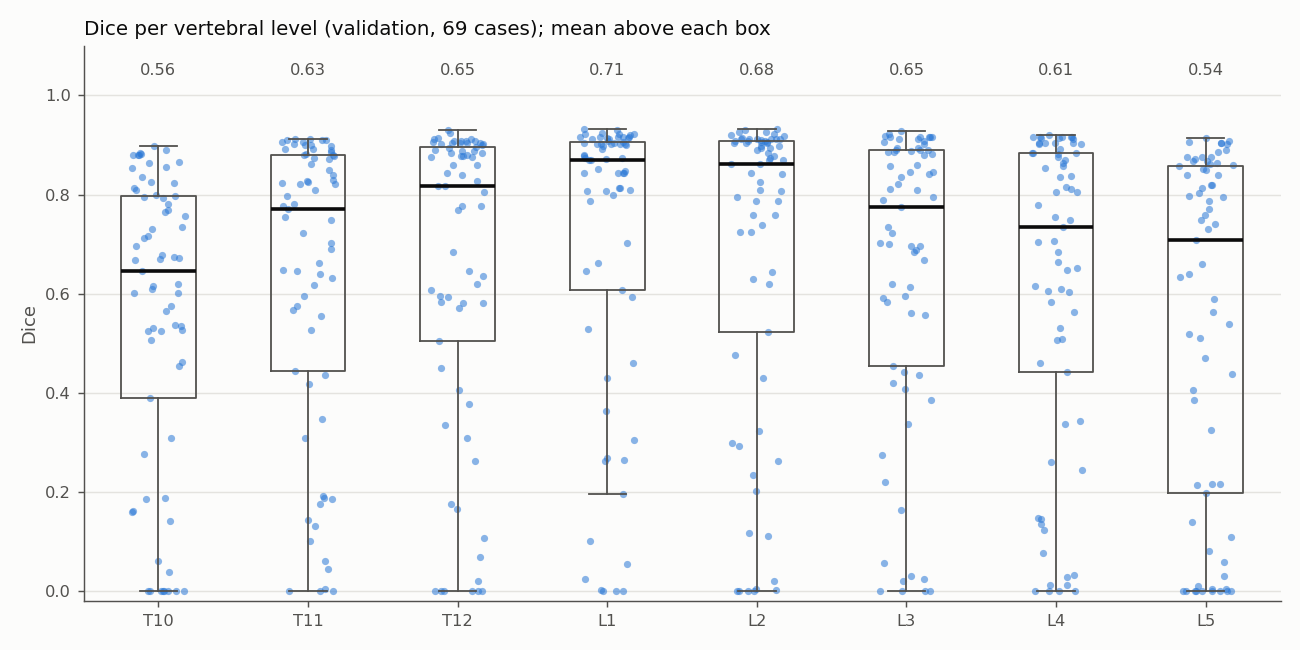

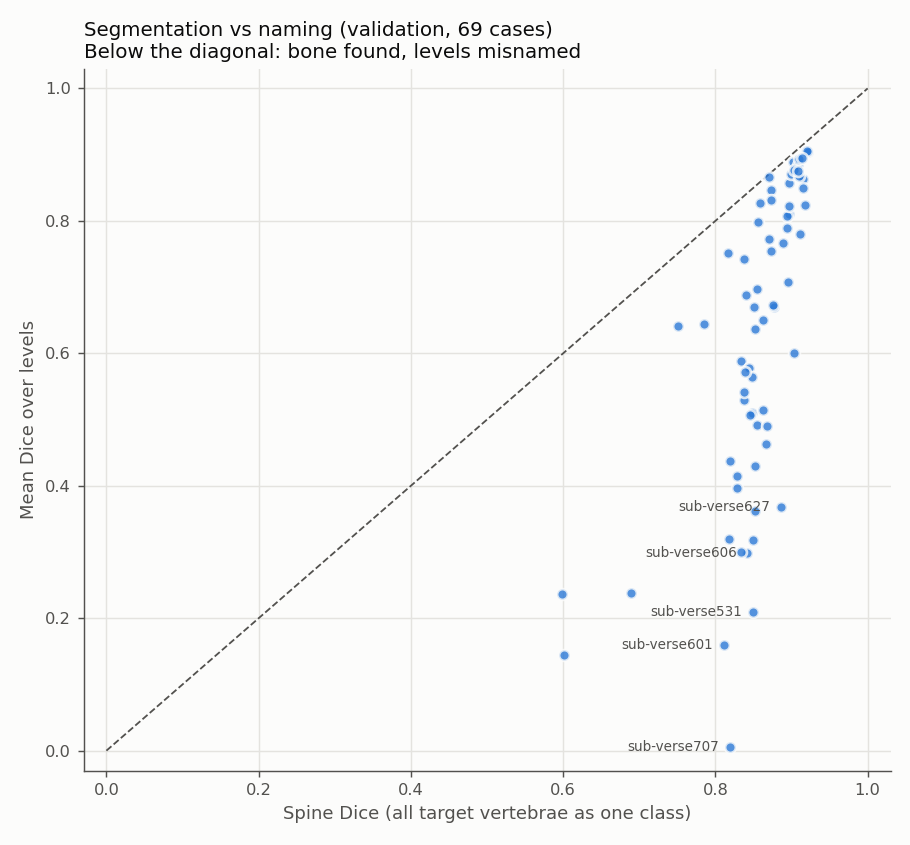

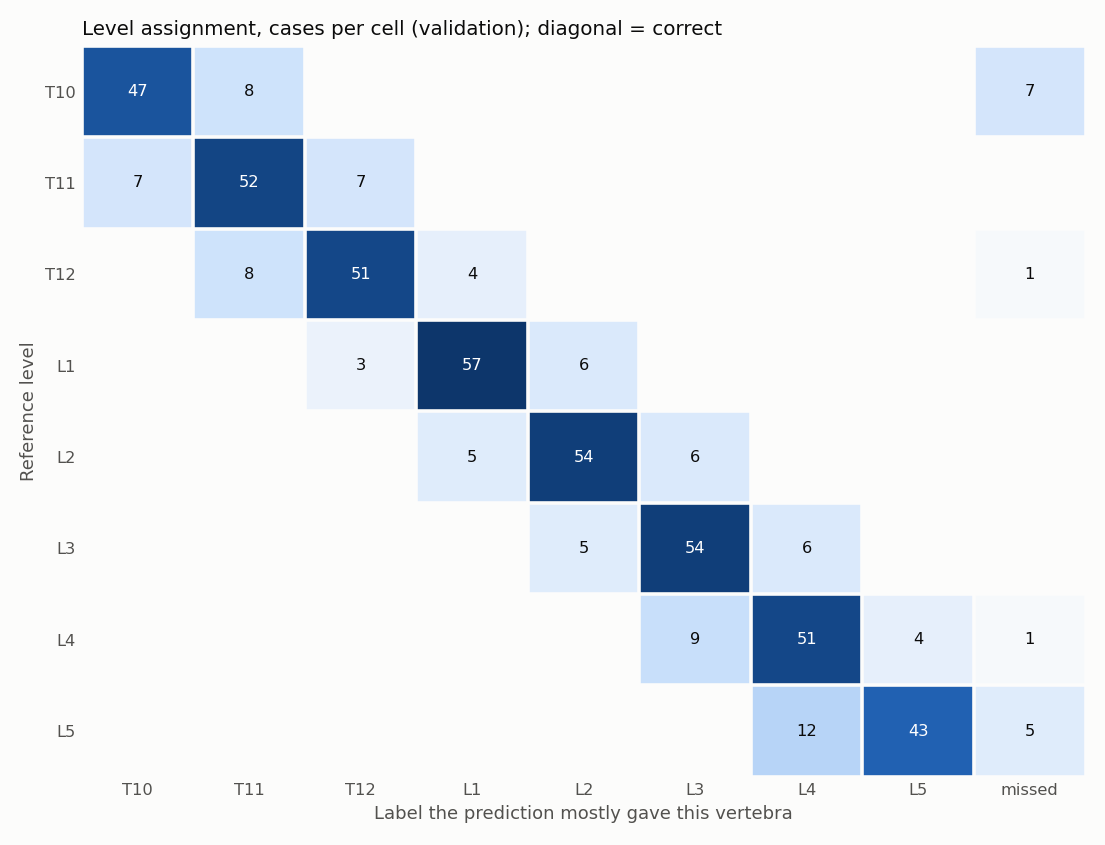

In [9]:
from IPython.display import Image, Markdown, display
out = REPO / 'outputs/evaluation' / RUN / 'validation'
display(Markdown((out / 'report.md').read_text(encoding='utf-8')))
for name in ('dice_per_level.png', 'spine_vs_level_dice.png', 'level_assignment.png'):
    display(Image(str(out / 'figures' / name), width=760))

---
## 8. Final test (run once, only when the model is frozen)
Repeats steps 3–6 on the 60 test cases. Do this only after the validation analysis is finished and the team agrees the model will not change. Then set `RUN_FINAL_TEST = True`.

The first final test records the model's fingerprint in `test_lock.json`. A later test with a different model is refused, so the test set cannot be used for tuning.

The first time, it downloads about 14 GB of VerSe test data and keeps a copy in Drive. Results are zipped as `test_results.zip`.

In [10]:
RUN_FINAL_TEST = False

if not RUN_FINAL_TEST:
    print('Final test is locked. Set RUN_FINAL_TEST = True only after the team freezes the model.')
else:
    m2_ok = extract_processed('test')
    place_verse(get_verse_zip('dataset-verse20test.zip'), 'test.csv')
    assert not raw_missing('test.csv'), 'some VerSe test files are missing: send this output to Claude'
    if not m2_ok:
        sh('python scripts/prepare_data.py --splits test')
    sh(f'python scripts/predict_split.py --split test --final-test --checkpoint best.pt --run-name {RUN} --device cuda')
    sh(f'python scripts/evaluate_segmentation.py --split test --final-test --pred-dir outputs/predictions/{RUN}/test')
    out_t = REPO / 'outputs/evaluation' / RUN / 'test'
    shutil.copytree(out_t, f'{RESULTS}/evaluation/test', dirs_exist_ok=True,
                    ignore=lambda d, names: ['cases'] if Path(d) == out_t else [])
    shutil.copy(REPO / 'outputs/evaluation/test_lock.json', f'{RESULTS}/evaluation/test_lock.json')
    sh(f'cd outputs/evaluation/{RUN} && zip -qr "{OUT_BASE}/test_results.zip" test -x "test/cases/*"')
    print('test results in', RESULTS)

Final test is locked. Set RUN_FINAL_TEST = True only after the team freezes the model.


## 9. Package the outputs for GitHub
Collects the outputs that belong in the repository into `outputs_for_github.zip` in your Drive folder, already in their repository paths: tables, reports, summary plots, `test_lock.json` and the prediction manifests. Extract it at the repository root.

Not included, on purpose: per-case figures (they show CT slices), per-case caches and the predicted masks (`.nii.gz`). These stay in Drive.

In [11]:
sh(f'rm -f "{OUT_BASE}/outputs_for_github.zip" && zip -qr "{OUT_BASE}/outputs_for_github.zip" '
   f'outputs/evaluation outputs/predictions -x "*/cases/*" "*.nii.gz" "*.tmp"')
sh(f'unzip -l "{OUT_BASE}/outputs_for_github.zip"')

$ rm -f "/content/drive/MyDrive/outputs_for_github.zip" && zip -qr "/content/drive/MyDrive/outputs_for_github.zip" outputs/evaluation outputs/predictions -x "*/cases/*" "*.nii.gz" "*.tmp"
$ unzip -l "/content/drive/MyDrive/outputs_for_github.zip"
Archive:  /content/drive/MyDrive/outputs_for_github.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
        0  2026-11-14 13:37   outputs/evaluation/
        0  2026-11-14 13:37   outputs/evaluation/baseline_96/
        0  2026-11-14 14:06   outputs/evaluation/baseline_96/validation/
      244  2026-11-14 14:06   outputs/evaluation/baseline_96/validation/level_assignment.csv
     8937  2026-11-14 14:06   outputs/evaluation/baseline_96/validation/summary.json
     1335  2026-11-14 14:06   outputs/evaluation/baseline_96/validation/summary_per_level.csv
      554  2026-11-14 14:06   outputs/evaluation/baseline_96/validation/confusion_voxels.csv
        0  2026-11-14 14:06   outputs/evaluation/baseline_96/validation/figur